# Reduced attitude control

A quadrotor's thrust direction determines the direction of its propulsive force. We consider two controllers: one aligns the thrust direction with the vertical, and the other makes it rotate around a prescribed cone. We test whether a learned model preserves these known behaviors when the topological computation is performed in one dimension.

The model is trained on the invariant subsystem with zero angular-velocity tracking error. It predicts the thrust direction, not the full quadrotor state.

## Setup

The saved outputs can be read without running Python. This notebook uses the legacy six-checkpoint experiment at revision `eaf94a7c45c150e2d2f0b42dec204e82a3c14a66`. The current repository's runnable workflow is [ex3_attitude_control.ipynb](../../ex3_attitude_control.ipynb).

To reproduce this notebook's outputs, create a separate checkout of the legacy source and copy this notebook and its plotting helper into it. Run these commands from the current repository root:

```bash
git worktree add --detach ../attitude-legacy eaf94a7c45c150e2d2f0b42dec204e82a3c14a66
cp code-kaito/notebooks/03_attitude.ipynb ../attitude-legacy/code-kaito/notebooks/
cp code-kaito/src/notebook_attitude_figures.py ../attitude-legacy/code-kaito/src/
cd ../attitude-legacy/code-kaito
```

Follow that checkout's `code-kaito/README.md` to prepare the notebook kernel. The notebook launches the saved-checkpoint computation in a separate environment. From its `code-kaito/` directory, prepare that environment with:

```bash
uv venv .venv-attitude --python 3.13
uv pip install --python .venv-attitude/bin/python -r ../code/requirements.txt
```

Graphviz (`dot`) renders the graphs and Poppler (`pdftoppm`) converts them to PNG. Both must be on `PATH`. Run cells in order. The walkthrough regenerates trajectory data and evaluates six saved checkpoints. The separate final cell repeats the experiment for comparison with the frozen reference. It does not retrain. Logs and editable figure exports go to `build/notebooks/attitude/`.

`ROOT` is `code-kaito/`, and `EXPERIMENT` is `code/examples/example3/periodic/`. NumPy handles arrays, SciPy integrates the height equation, and Matplotlib draws the plots. The following source files contain the controller, learned model, and analysis functions:

| Task | Source and entry point | Inputs and outputs |
|---|---|---|
| Physical feedback | [`controller.py`](https://github.com/bernardorivas/2027_L4DC_EquivariantMorseGraphs/blob/eaf94a7c45c150e2d2f0b42dec204e82a3c14a66/code/examples/example3/periodic/controller.py), `field`, `rhs` | Rigid-body state and controller choice → vector field and state derivative |
| Learned maps and loss | [`model.py`](https://github.com/bernardorivas/2027_L4DC_EquivariantMorseGraphs/blob/eaf94a7c45c150e2d2f0b42dec204e82a3c14a66/code/examples/example3/periodic/model.py), `OrbitModel`, `pieces` | Observations and saved parameters → encoded states, predictions, seven losses |
| Full replay | [`run.py`](https://github.com/bernardorivas/2027_L4DC_EquivariantMorseGraphs/blob/eaf94a7c45c150e2d2f0b42dec204e82a3c14a66/code/examples/example3/periodic/run.py), `replay` | Fresh output directory → regenerated data, checked metrics and graphs |
| Cell images and indices | [`analysis.py`](https://github.com/bernardorivas/2027_L4DC_EquivariantMorseGraphs/blob/eaf94a7c45c150e2d2f0b42dec204e82a3c14a66/code/examples/example3/periodic/analysis.py), `graph` | Interval map → sampled cell graph, Morse components and indices |
| Graph drawing | [`notebook_attitude_figures.py`](../src/notebook_attitude_figures.py), `graph` | Graph record → Graphviz source |
| Sphere drawing | [`notebook_attitude_figures.py`](../src/notebook_attitude_figures.py), `sphere` | Cell membership and coordinate knots → sphere bands and height strip |


In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "upstream.json").is_file())
EXPERIMENT = ROOT.parent / "code" / "examples" / "example3" / "periodic"
REPORT = EXPERIMENT / "reference" / "summary.json"
if not REPORT.is_file():
    raise FileNotFoundError("Clone the complete repository, including code/examples/example3/periodic/reference.")
rows = json.loads(REPORT.read_text())
assert {(r["policy"], r["seed"]) for r in rows} == {(p, s) for p in ("nominal", "coning") for s in range(3)}
OUT = ROOT / "build" / "notebooks" / "attitude"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
print("Loaded saved reports for two controllers and three seeds each.")
import sys
sys.path.insert(0, str(ROOT / "src"))
import notebook_attitude_figures as presentation
plt.rcParams.update(presentation.FONT)


Loaded saved reports for two controllers and three seeds each.


## Controlled motion and physical quotient

The rigid-body state is $(p,v,R,\Omega)\in\mathbb R^3\times\mathbb R^3\times\mathrm{SO}(3)\times\mathbb R^3$. Position and velocity are $p,v$, orientation is $R$, and body angular velocity is $\Omega$. The thrust direction is $q=Re_3\in S^2$, where $e_3=(0,0,1)$. Write $z=q\cdot e_3$ and $w=R\Omega$.

For a gain $a:[-1,1]\to\mathbb R$, prescribe
$$V_a(q)=a(z)(e_3-zq)+\omega e_3\times q,\qquad \omega=\pi/\log2.$$
The first term changes the tilt, while the second rotates the thrust direction about the vertical. Both are tangent to the sphere. Define $w_d(q)=q\times V_a(q)$ and the rate error $\eta=w-w_d(q)$. With inertia matrix $J$, the control moment is
$$M=\Omega\times J\Omega+JR^\top\bigl(Dw_d(q)[w\times q]-2\eta\bigr).$$
Here $Dw_d(q)[h]$ is the directional derivative in direction $h$. For tangent $h$ it is
$$Dw_d(q)[h]=a'(z)h_3(q\times e_3)+a(z)(h\times e_3)-\omega(h_3q+zh).$$
Substitution into the rigid-body equations gives
$$\dot q=V_a(q)+\eta\times q,\qquad \dot\eta=-2\eta.$$
Thus $\eta=0$ is invariant. All training trajectories start there, so the thrust direction evolves autonomously under a flow $F_t:S^2\to S^2$. For mass $\mu$ and gravitational acceleration $g$, the thrust magnitude is fixed at $\mu g$, giving $\dot v=g(q-e_3)$. This controller regulates the thrust direction but not position, so a coning thrust direction need not produce a periodic flight path.

### Removing rotation about the vertical

For a rotation $Q\in\mathrm{SO}(2)$ about $e_3$, the state action is $(p,v,R,\Omega)\mapsto(Qp,Qv,QR,\Omega)$ and $q\mapsto Qq$. The height projection $\pi:S^2\to[-1,1]$, $\pi(q)=q_3$, identifies directions that differ only by such a rotation. On $\eta=0$,
$$\dot z=e_3\cdot V_a(q)=a(z)(1-z^2).$$
The quotient flow $h_t:[-1,1]\to[-1,1]$ satisfies $\pi\circ F_t=h_t\circ\pi$. Away from the poles the azimuth satisfies $\dot\varphi=\omega$.

| Controller | Gain $a(z)$ | Attracting behavior | Exceptional initial directions |
|---|---|---|---|
| Nominal | $1$ | Upright direction $q=e_3$ | The downward pole remains fixed |
| Coning | $1/4-z$ | Circle $q_3=1/4$, with period $2\log2$ | Both poles remain fixed |

For example, $(\sqrt3/2,0,1/2)$ and $(0,\sqrt3/2,1/2)$ represent the same quotient state. At this height the nominal controller gives $\dot z=3/4$, while coning gives $\dot z=(1/4-1/2)(1-1/4)=-3/16$. The first moves toward upright alignment, and the second moves toward the prescribed cone. An equilibrium of the height equation can therefore represent a rotating circle rather than a stationary thrust direction.

### Height trajectories

`height_rhs` implements the scalar equation above. `solve_ivp` integrates several independent initial heights together. Solid curves show these trajectories, and dashed lines mark fixed heights. In the coning plot, height approaches $1/4$ while the azimuth continues to rotate.

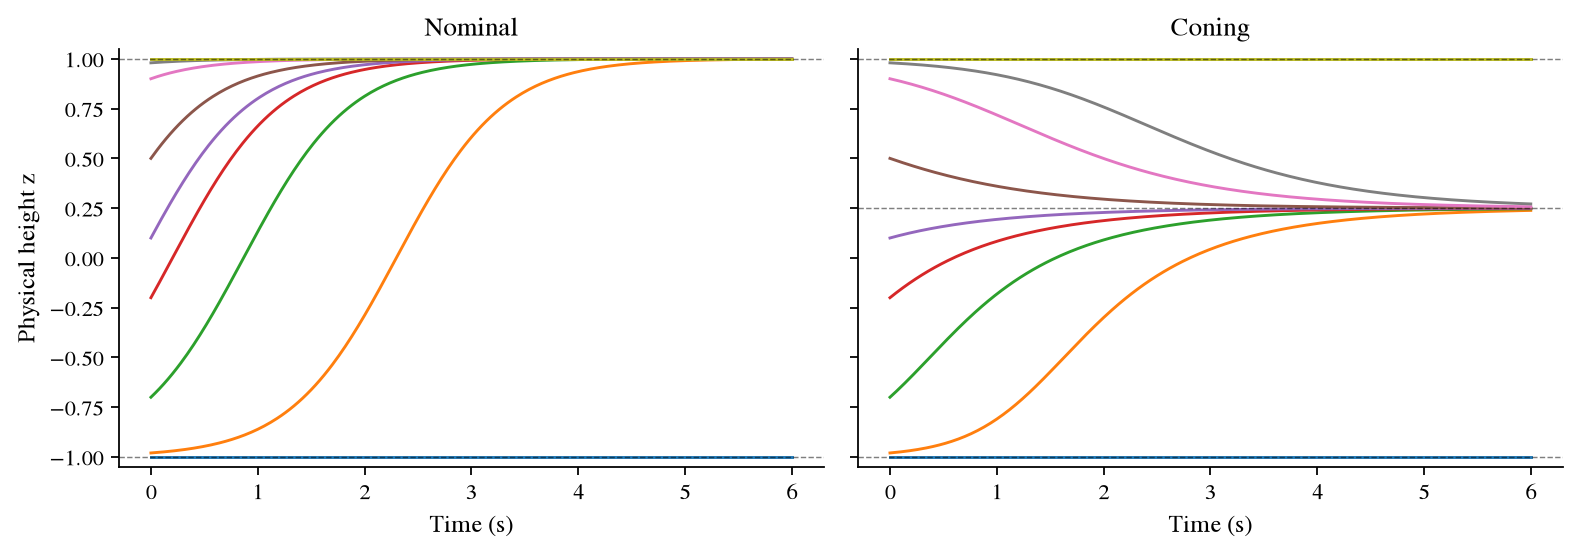

In [2]:
plt.rcParams.update(presentation.FONT)
def height_rhs(t, z, policy):
    gain = np.ones_like(z) if policy == "nominal" else 0.25 - z
    return gain * (1 - z*z)

times = np.linspace(0, 6, 301)
starts = np.array([-1., -.98, -.7, -.2, .1, .5, .9, .98, 1.])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, policy in zip(axes, ("nominal", "coning")):
    sol = solve_ivp(lambda t, z: height_rhs(t, z, policy), (0, 6), starts,
                    t_eval=times, rtol=1e-10, atol=1e-12)
    assert sol.success and np.max(np.abs(sol.y)) <= 1 + 1e-9
    for curve in sol.y:
        ax.plot(times, curve, linewidth=1.3)
    equilibria = [-1, 1] if policy == "nominal" else [-1, .25, 1]
    assert np.allclose(height_rhs(0, np.array(equilibria), policy), 0)
    for z in equilibria:
        ax.axhline(z, color="black", linestyle="--", linewidth=.65, alpha=.5)
    ax.set(title=policy.capitalize(), xlabel="Time (s)", ylim=(-1.05, 1.05))
axes[0].set_ylabel("Physical height z")
fig.tight_layout()
for suffix in ("png", "pdf", "svg"):
    fig.savefig(OUT / f"physical-height-trajectories.{suffix}", dpi=160, bbox_inches="tight")
presentation.show_plot(fig)

## Encoder, time-step map, and decoder

The encoder maps observations to a latent sphere equivariantly: rotating the plant about the vertical rotates the latent vector by the same angle. Taking its height then reduces the dynamics to an interval. In Examples 1 and 2, the encoder maps directly to invariant coordinates.

Let $o=(p,v,Re_1,Re_2,Re_3,\Omega)\in\mathcal O\subset\mathbb R^{18}$ be the observation. The target $q(o)=Re_3$ is already present in entries `12:15`. For rotation $Q$ about the vertical, the first five vector blocks rotate by $Q$ and body angular velocity stays fixed. The EMLP representation enforces this action. An EMLP is a neural network whose layers commute with the specified group action.

The encoder $E:\mathcal O\to Z=S^2$ and decoder $D:Z\to S^2$ have raw equivariant networks $N_E,N_D$:
$$E(o)=\nu\bigl(N_E(S^{-1}(o-\mu_o))\bigr),\qquad D(\ell)=\nu(N_D(\ell)),\qquad
\nu(y)=\frac{y}{\max(\|y\|,10^{-12})}.$$
The saved mean $\mu_o$ and diagonal scale $S$ come from training observations. For each of the first five vector blocks, only its vertical mean is removed and one RMS scale is shared across the block. Body-rate entries use componentwise means and standard deviations. The thrust-direction block is overridden to mean zero and scale one. These operations respect the group action. Unit output requires the raw norm to be at least the numerical floor. The held-out checks support the sphere interpretation, but do not prove global nonvanishing.

Here $\ell=(\ell_1,\ell_2,\zeta)\in Z$ denotes a latent vector. The learned map $f:Z\to Z$ advances **0.1 seconds**. Its scalar network outputs $B(\zeta),A(\zeta)$, from which we define
$$b(\zeta)=0.5\tanh B(\zeta),\qquad \alpha(\zeta)=\tanh A(\zeta).$$
Writing $d(\zeta)=\cosh b(\zeta)+\zeta\sinh b(\zeta)$, the full map is
$$f(\ell)=\frac{1}{d(\zeta)}\begin{pmatrix}
\cos\alpha(\zeta)\,\ell_1-\sin\alpha(\zeta)\,\ell_2\\
\sin\alpha(\zeta)\,\ell_1+\cos\alpha(\zeta)\,\ell_2\\
\zeta\cosh b(\zeta)+\sinh b(\zeta)
\end{pmatrix}.$$
The denominator is positive on $[-1,1]$, and this formula preserves the sphere and fixes both poles. Its height map is
$$\bar f(\zeta)=\frac{\zeta\cosh b(\zeta)+\sinh b(\zeta)}{d(\zeta)}.$$
Interior fixed heights satisfy $b(\zeta)=0$. The angle $\alpha(\zeta)$ determines the rotation along each such circle. The desired prediction is $D(f^j(E(o_0)))\approx q(o_j)$ for observations $0.1j$ seconds apart.

### Learned interval coordinate

The height projection is $\pi_Z(\ell)=\zeta$. A learned increasing piecewise-linear homeomorphism $\psi:[-1,1]\to[-1,1]$ gives $u=\psi(\zeta)$. Its 33 equally spaced input knots are $\kappa_i=-1+i/16$, $i=0,\ldots,32$. A scalar network $c$ defines positive increments
$$\delta_i=\exp\!\left(0.35\tanh c\left(\frac{\kappa_i+\kappa_{i+1}}2\right)\right),\qquad
\psi(\kappa_j)=-1+2\frac{\sum_{i<j}\delta_i}{\sum_{i=0}^{31}\delta_i}.$$
Linear interpolation defines $\psi$ between knots. Positive increments guarantee an increasing inverse. A separate interval decoder $\rho:[-1,1]\to[-1,1]$ uses the same construction with its own network. It is trained to recover latent height and is not set equal to $\psi^{-1}$.

The interval encoder is $\psi\circ\pi_Z\circ E$, and its time-step map is $\psi\circ\bar f\circ\psi^{-1}$. Thus $\pi_Z\circ f=\bar f\circ\pi_Z$ holds by construction. The topological computation uses $(\psi\circ\bar f\circ\psi^{-1})^{10}$, corresponding to one second. Thus the physical height $z$, encoded height $\zeta$, and interval coordinate $u$ must be distinguished when comparing the learned and physical dynamics.

## Training objective

Let $o_j$ be an observation at time $t+0.1j$, with $j\in\mathcal H=\{0,1,4,10\}$. Define $q_j=q(o_j)$, $\ell_j=E(o_j)$, $\widehat\ell_j=f^j(E(o_0))$, $\zeta_j=\pi_Z(\ell_j)$, and $\widehat\zeta_j=\pi_Z(\widehat\ell_j)$. Predictions use $\mathcal H_+=\{1,4,10\}$. For vector errors, squared norms below are divided by three to match the code's mean over coordinates. Every expectation is an empirical average over the batch and the indicated horizons.

| Term | Formula | Purpose |
|---|---|---|
| Reconstruction | $L_{\rm rec}=\mathbb E\Vert D(\ell_0)-q_0\Vert ^2/3$ | Recover the initial thrust direction |
| Prediction | $L_{\rm pred}=\mathbb E_{j\in\mathcal H_+}\Vert D(\widehat\ell_j)-q_j\Vert ^2/3$ | Predict future thrust directions |
| Encoder supervision | $L_{\rm cal}=\mathbb E_{j\in\mathcal H}\Vert \ell_j-q_j\Vert ^2/3$ | Keep the latent vector close to the known thrust direction |
| Latent consistency | $L_{\rm con}=\mathbb E_{j\in\mathcal H_+}\Vert \widehat\ell_j-\ell_j\Vert ^2/3$ | Match predicted and encoded latent states |
| Height reconstruction | $L_{\rm hr}=\mathbb E_{j\in\mathcal H}(\rho(\psi(\zeta_j))-\zeta_j)^2$ | Decode the interval coordinate |
| Height prediction | $L_{\rm hp}=\mathbb E_{j\in\mathcal H_+}(\rho(\psi(\widehat\zeta_j))-\zeta_j)^2$ | Predict latent height |
| Interval consistency | $L_{\rm ic}=\mathbb E_{j\in\mathcal H_+}(\psi(\widehat\zeta_j)-\psi(\zeta_j))^2$ | Compare predictions in the learned interval coordinate |

The joint objective is
$$L=L_{\rm rec}+3L_{\rm pred}+2L_{\rm cal}+0.5(L_{\rm con}+L_{\rm hr}+L_{\rm hp})+0.1L_{\rm ic}.$$
The first 1,000 updates instead use $L_{\rm rec}+4L_{\rm cal}+0.5L_{\rm hr}$. These definitions correspond to `pieces` in `model.py`. The known thrust direction supervises the encoder, so this experiment does not discover an unknown physical reduction.

## Saved models and training settings

Each controller uses 8,192 training, 2,048 validation, and 4,096 test trajectories. Each has 33 observations at 0.1-second spacing. The physical simulator uses normalized-quaternion RK4 with step 0.002 seconds. Initial states satisfy $\eta=0$, with a quarter of heights near the poles.

The sphere networks have width 64 and two hidden layers. Scalar heads have width 24, and $\psi$ uses 33 knots. Training uses batches of 256, a 1,000-update calibration stage, and joint fitting through update 6,000. Prediction horizons are 1, 4, and 10 steps. The optimizer is AdamW with weight decay $10^{-6}$ and gradient norm clipped at 1. Its cosine learning-rate schedule decreases from $0.002$ to $0.00005$.

The joint validation objective selects checkpoints and seeds before graph computation. The table reports all six fits.

## Evaluating the saved models

The next cell regenerates the trajectories and evaluates the six saved models, using the experiment's data generator and analysis functions. It computes prediction errors, interval graphs, and their grouped indices without training. The figures below use these newly computed results.

The final reproducibility check compares an independent replay with the frozen reference. It is separate from the figure walkthrough, so a reference mismatch does not prevent the plots from being generated. Numerical or graph-construction errors in the computation itself still stop execution.


In [3]:
import os, sys, subprocess, tempfile
REPLAY_PYTHON = ROOT / ".venv-attitude" / "bin" / "python"
if not REPLAY_PYTHON.is_file():
    raise FileNotFoundError("Install .venv-attitude using the setup cell above.")
RUN = Path(tempfile.mkdtemp(prefix="replay-", dir=OUT))
REPLAY = RUN / "experiment"
log_path = RUN / "replay.log"
env = os.environ.copy()
env.update(MPLBACKEND="Agg", JAX_PLATFORM_NAME="cpu", MPLCONFIGDIR=str(OUT / "matplotlib"))
compute_script = """
from pathlib import Path
import shutil, sys
sys.path.insert(0, sys.argv[1])
from common.workflow import read, write, verify_inputs, require_environment
from example3.periodic import analysis, data, validation
experiment, out = Path(sys.argv[2]), Path(sys.argv[3])
require_environment(graphics=True)
verify_inputs(experiment)
config = read(experiment / "reference/requested-config.json")
out.mkdir()
data.generate(out / "data")
validation.physical_checks(out / "controller")
trained = out / "trained"
trained.mkdir()
write(trained / "requested-config.json", config)
for policy in config["policies"]:
    for seed in config["seeds"]:
        relative = Path(policy) / f"seed{seed}"
        shutil.copytree(experiment / "reference" / relative / "model", trained / relative / "model")
analysis.run(trained, out / "data", config["policies"], config["seeds"])
"""
print("Evaluating six saved models and computing their graphs. No retraining.", flush=True)
with log_path.open("w") as log:
    result = subprocess.run([str(REPLAY_PYTHON), "-c", compute_script,
                             str(EXPERIMENT.parents[1]), str(EXPERIMENT), str(REPLAY)],
                            cwd=ROOT.parent / "code", env=env,
                            stdout=log, stderr=subprocess.STDOUT)
if result.returncode:
    raise RuntimeError(f"Computation failed. See {log_path}\n" + log_path.read_text()[-5000:])
TRAINED = REPLAY / "trained"
rows = json.loads((TRAINED / "summary.json").read_text())
print(f"Computed results for {len(rows)} saved models. Reference comparison is at the end.")


Evaluating six saved models and computing their graphs. No retraining.


Computed results for 6 saved models. Reference comparison is at the end.


In [4]:
selected = {}
lines = ["| Controller | Seed | Validation objective | One-second axis RMS | Native nodes |",
         "|---|---:|---:|---:|---:|"]
for policy in ("nominal", "coning"):
    candidates = [r for r in rows if r["policy"] == policy]
    selected[policy] = min(candidates, key=lambda r: (r["metrics"]["validation"]["objective"], r["seed"]))
    for r in sorted(candidates, key=lambda r: r["seed"]):
        metrics = r["metrics"]
        lines.append(f"| {policy} | {r['seed']} | {metrics['validation']['objective']:.6g} | "
                     f"{metrics['forecast_rms_by_horizon'][10]:.7f} | {len(r['graph']['nodes'])} |")
display(Markdown("\n".join(lines)))
print("Validation-selected seeds:", {p: r["seed"] for p, r in selected.items()})

| Controller | Seed | Validation objective | One-second axis RMS | Native nodes |
|---|---:|---:|---:|---:|
| nominal | 0 | 2.02909e-06 | 0.0010055 | 2 |
| nominal | 1 | 3.95741e-06 | 0.0014311 | 2 |
| nominal | 2 | 3.80298e-06 | 0.0012477 | 2 |
| coning | 0 | 7.18923e-06 | 0.0018308 | 4 |
| coning | 1 | 9.8252e-06 | 0.0020604 | 4 |
| coning | 2 | 9.32039e-06 | 0.0017331 | 4 |

Validation-selected seeds: {'nominal': 0, 'coning': 0}


### Prediction errors

The curves below show prediction errors for the validation-selected fit of each controller.

At horizon $j$, the plotted error is $\sqrt{\mathbb E\|D(f^j(E(o_0)))-q_j\|^2/3}$ over 4,096 held-out trajectories. The horizontal axis is $0.1j$ seconds. At zero it measures reconstruction error. Later points repeatedly apply the same learned map without resetting to observations. This is componentwise thrust-direction RMS, not an angular error or a full-state error.

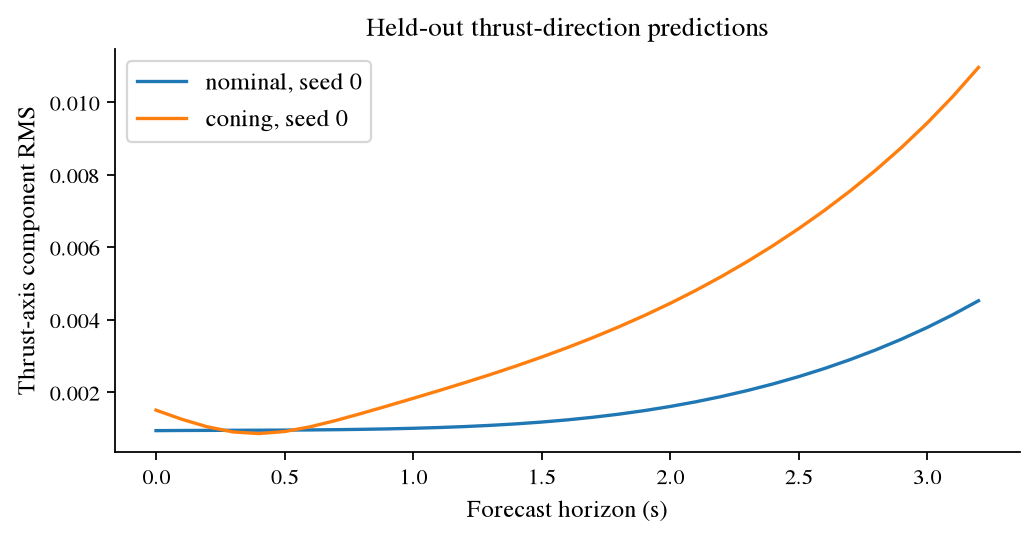

In [5]:
plt.rcParams.update(presentation.FONT)
fig, ax = plt.subplots(figsize=(6.6, 3.5))
for policy, row in selected.items():
    errors = np.array(row["metrics"]["forecast_rms_by_horizon"])
    ax.plot(.1*np.arange(len(errors)), errors, label=f"{policy}, seed {row['seed']}")
ax.set(xlabel="Forecast horizon (s)", ylabel="Thrust-axis component RMS", title="Held-out thrust-direction predictions")
ax.legend()
fig.tight_layout()
for suffix in ("png", "pdf", "svg"):
    fig.savefig(OUT / f"saved-axis-errors.{suffix}", dpi=160, bbox_inches="tight")
presentation.show_plot(fig)

### Physical, latent, and interval coordinates

Each row below uses the validation-selected checkpoint. The left panel compares physical height $z=q_3$ with encoded latent height $\zeta=\pi_Z(E(o))$ on held-out observations. Encoder supervision encourages proximity to the diagonal, but does not impose equality. The middle panel shows $u=\psi(\zeta)$. The right shows the one-step displacement $\bar f(\zeta)-\zeta$, whose zeros are fixed latent heights. The graph computation later uses ten steps.

The replay saves these arrays in `diagnostics.npz`, using `diagnostics` in `periodic/analysis.py`. The plotting cell also checks that the learned coordinate is increasing and fixes both endpoints.

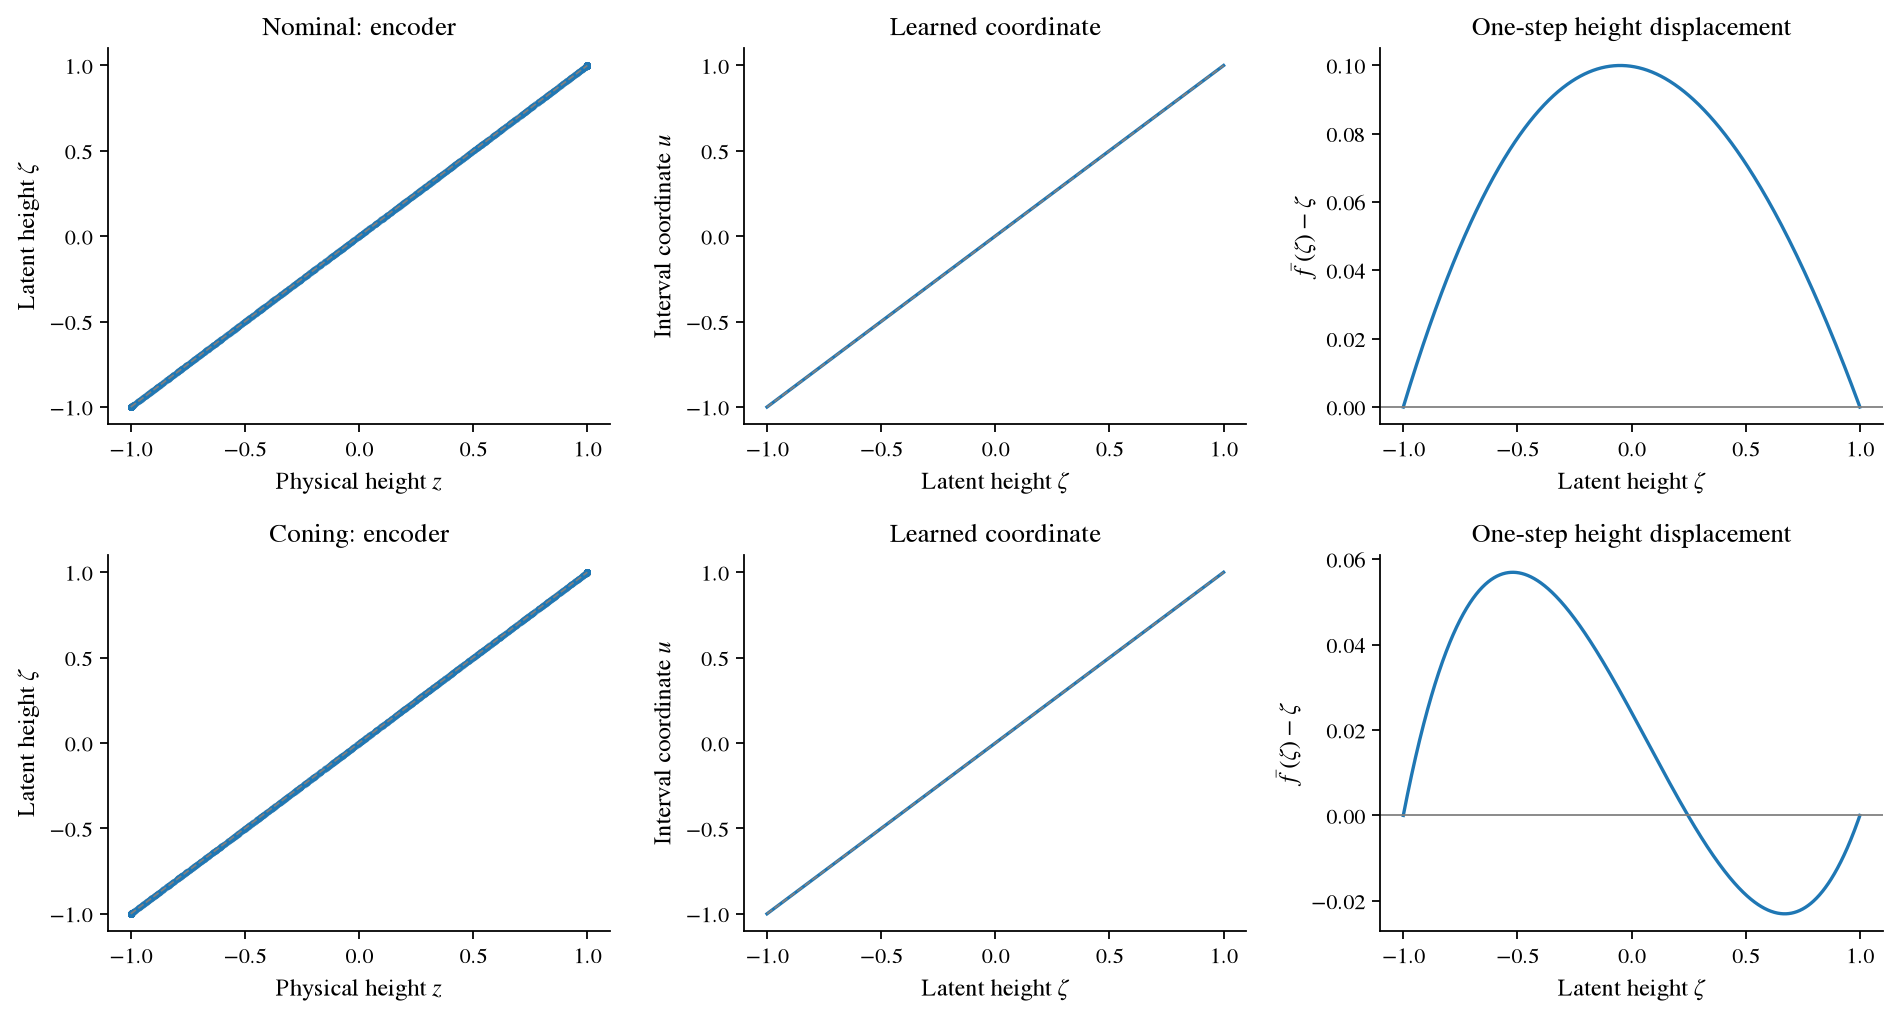

In [6]:
plt.rcParams.update(presentation.FONT)
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for row_index, policy in enumerate(("nominal", "coning")):
    seed = selected[policy]["seed"]
    folder = TRAINED / policy / f"seed{seed}"
    with np.load(folder / "diagnostics.npz") as saved:
        arrays = {key: saved[key] for key in saved.files}
    latent_height = arrays["heights"]
    knots, values = arrays["knots"], arrays["coordinate_values"]
    assert np.all(np.diff(values) > 0)
    np.testing.assert_allclose(values[[0, -1]], [-1, 1], atol=1e-7)
    ax = axes[row_index, 0]
    ax.scatter(arrays["test_physical_axis"][:, 2], arrays["test_latent_axis"][:, 2],
               s=3, alpha=.2, rasterized=True)
    ax.plot([-1, 1], [-1, 1], color=".5", linestyle="--", linewidth=.8)
    ax.set(xlabel="Physical height $z$", ylabel=r"Latent height $\zeta$",
           title=f"{policy.capitalize()}: encoder")
    ax = axes[row_index, 1]
    ax.plot(knots, values)
    ax.plot([-1, 1], [-1, 1], color=".5", linestyle="--", linewidth=.8)
    ax.set(xlabel=r"Latent height $\zeta$", ylabel="Interval coordinate $u$",
           title="Learned coordinate")
    ax = axes[row_index, 2]
    ax.plot(latent_height, arrays["latitude"] - latent_height)
    ax.axhline(0, color=".5", linewidth=.8)
    ax.set(xlabel=r"Latent height $\zeta$", ylabel=r"$\bar f(\zeta)-\zeta$",
           title="One-step height displacement")
fig.tight_layout()
for suffix in ("png", "pdf", "svg"):
    fig.savefig(OUT / f"learned-coordinate-diagnostics.{suffix}", dpi=160, bbox_inches="tight")
presentation.show_plot(fig)

## Morse graphs and index annotations

CMGDB analyzes $(\psi\circ\bar f\circ\psi^{-1})^{10}$ on 128 interval cells. `analysis.py::graph` samples 257 points in each cell and takes the minimum and maximum images, padded by $2\times10^{-6}$ and clipped to $[-1,1]$. It creates a directed edge from a cell to every cell meeting that interval. These sampled hulls are not certified enclosures.

A **Morse component** is represented by recurrent, mutually reachable cells in this directed graph. A node collects such a component. An arrow between nodes records reachability in the finite graph, not a proof of a connecting physical trajectory. A **sink** has no outgoing edge to another node. An **aggregate** merges components and all cells on directed paths between them. The merged index pair is checked and its index recomputed, because merging changes the index pair.

The nominal computation has two nodes. The coning computation has four before grouping, including a one-cell component with zero Conley index adjacent to the attracting component. Merging these gives three nodes. Zero index alone does not prove the extra component contains no dynamics.

### Reading the node labels

$N$ and $S$ label the north and south pole components, $C$ the coning component, and $A$ the additional component before merging. The letter labels and colors remain consistent before and after grouping.

For an index pair $(N_0,L_0)$, relative homology $H_k(N_0,L_0;\mathbb F_5)$ records the neighborhood relative to its exit set. Here $\mathbb F_5$ is the field of integers modulo five. Tuples list index-map polynomials in increasing degree. In these outputs, `x-1` denotes a one-dimensional surviving class with identity action and `0` a trivial Conley-index entry. The `x` is a formal polynomial variable, not a state coordinate. For example, `(x-1, 0)` is the interval index of the attracting component.

### Analytical thrust-axis indices

An interior height represents a circle, while an endpoint represents a single pole. Consequently, an interval annotation cannot simply be reused on the sphere. For the physical thrust-axis dynamics, a repelling pole has nonzero relative homology only in degree 2, the upright sink only in degree 0, and the attracting coning circle in degrees 0 and 1. Their time-map actions are identities.

The sphere-index panels assign these **analytical** tuples by node label. They describe the physical thrust-axis dynamics, rather than an independently computed index of the learned sphere map or the full plant.

## Graphs and sphere preimages

The first row for each controller compares the interval graph before and after grouping. The second shows the grouped cells on the latent sphere beside the analytical thrust-axis indices. A cell $[u_-,u_+]$ corresponds to the latitude band $\psi^{-1}(u_-)\leq\zeta\leq\psi^{-1}(u_+)$. These are latent-sphere preimages, not physical inverse images under the full-state encoder.

Dark bands mark Morse cells, and pale shading marks the computed attracting region. Fainter arcs lie behind the sphere. The attracting component is blue, the south pole is vermilion, and the coning north pole is green, as in the paper.

The plotting cell reads the recomputed cell records and learned coordinate from the selected models. It saves editable Graphviz files and PDF/SVG panels using the presentation functions in `src/notebook_attitude_figures.py`.


In [7]:
FIGURES = RUN / "figures"
FIGURES.mkdir()
render_script = """
from pathlib import Path
import json,sys,subprocess
import numpy as np
sys.path.insert(0,sys.argv[1])
from common.render_attitude import roles, sphere_indices
sys.path.insert(0,sys.argv[4])
import notebook_attitude_figures as presentation
out=Path(sys.argv[2]); trained=Path(sys.argv[3])
selection=json.loads((trained/"selection.json").read_text())
for policy, chosen in selection.items():
    folder=trained/policy/f"seed{chosen['selected_seed']}"
    target=out/policy;target.mkdir(exist_ok=True)
    raw=json.loads((folder/"cmgdb/results.json").read_text())
    aggregate=json.loads((folder/"cmgdb/aggregate/results.json").read_text())
    assert aggregate["aggregation"]["index_pairs_checked"]
    for name,record,reconstructed in [("native",raw,False),("aggregate",aggregate,False),("reconstructed",aggregate,True)]:
        names=roles(record,policy)
        indices={row["node"]: (sphere_indices(names[row["node"]],policy) if reconstructed else row["annotations"]) for row in record["nodes"]}
        presentation.graph(names,record["edges"],names,policy,indices,target/name)
    with np.load(folder/"cmgdb/aggregate/phase.npz") as saved:
        phase={k:saved[k] for k in saved.files}
    with np.load(folder/"diagnostics.npz") as saved:
        coordinate={"knots":saved["knots"],"values":saved["coordinate_values"]}
    presentation.sphere(phase["boxes"],phase["membership"],coordinate["knots"],coordinate["values"],roles(aggregate,policy),policy,target/"preimages",basin_labels=phase["basin_node"])
    for name in ["native","aggregate","preimages","reconstructed"]:
        subprocess.run(["pdftoppm","-scale-to","1100","-png","-singlefile",str(target/f"{name}.pdf"),str(target/name)],check=True,stdout=subprocess.DEVNULL,stderr=subprocess.DEVNULL)
"""
with (RUN / "figures.log").open("w") as log:
    result = subprocess.run([str(REPLAY_PYTHON), "-c", render_script,
                             str(EXPERIMENT.parents[1]), str(FIGURES), str(TRAINED), str(ROOT / "src")],
                            env=env, stdout=log, stderr=subprocess.STDOUT)
if result.returncode:
    raise RuntimeError((RUN / "figures.log").read_text()[-5000:])
print("Generated graphs and sphere preimages from the recomputed model outputs.")

Generated graphs and sphere preimages from the recomputed model outputs.


### Nominal control

The downward component $S$ leads to the upright sink $N$. No grouping is needed, so the two interval graphs agree. The zero interval index at $S$ does not contradict its nonzero analytical sphere index.

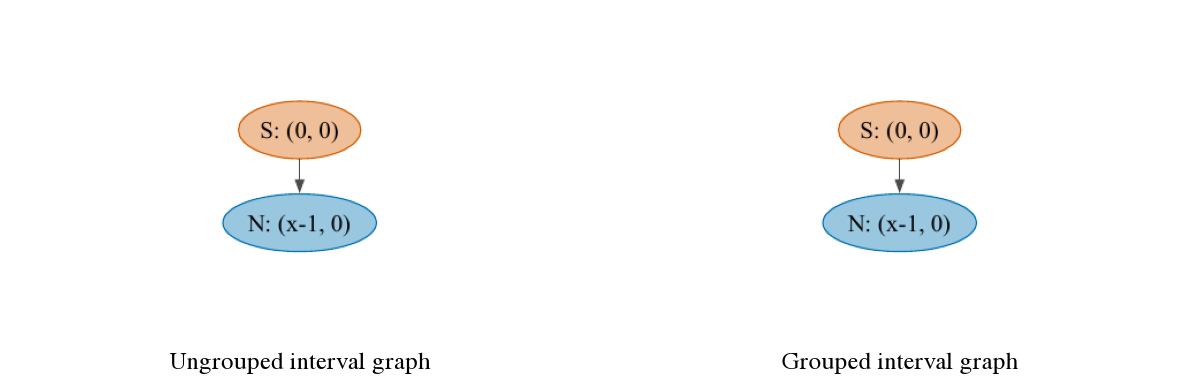

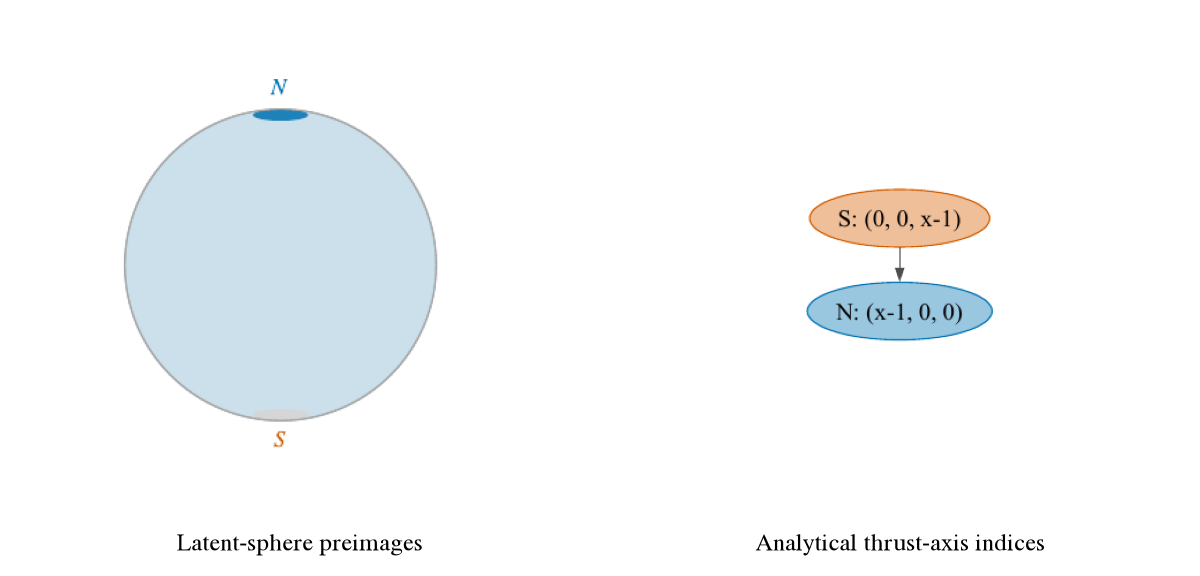

In [8]:
import notebook_attitude_figures as presentation
policy = "nominal"
for names, titles in [(('native', 'aggregate'), ('Ungrouped interval graph', 'Grouped interval graph')),
                      (('preimages', 'reconstructed'), ('Latent-sphere preimages', 'Analytical thrust-axis indices'))]:
    presentation.show([FIGURES / policy / f"{name}.pdf" for name in names], titles, width=750)


### Coning control

The ungrouped graph separates $A$ from $C$. The aggregate combines them and their connecting cells, then recomputes the interval index. The resulting graph has both pole components leading to $C$. Its sphere band lies near the prescribed physical height $1/4$, but is plotted in latent height.

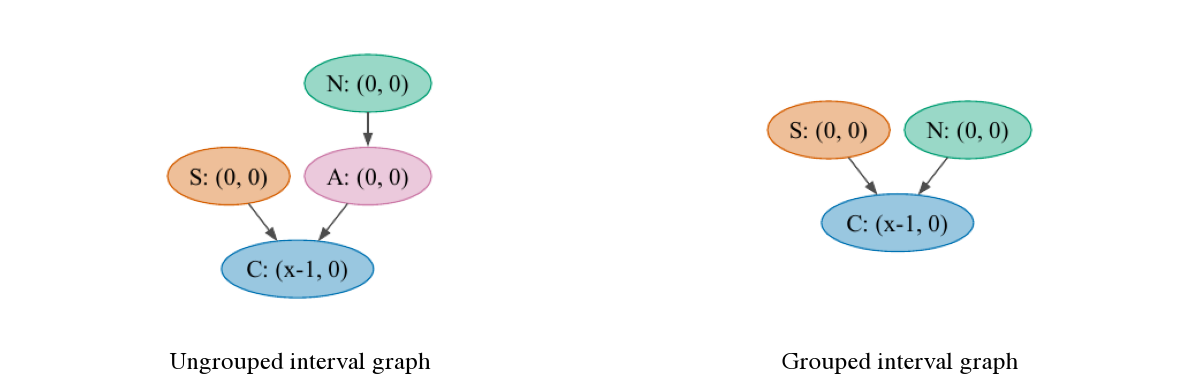

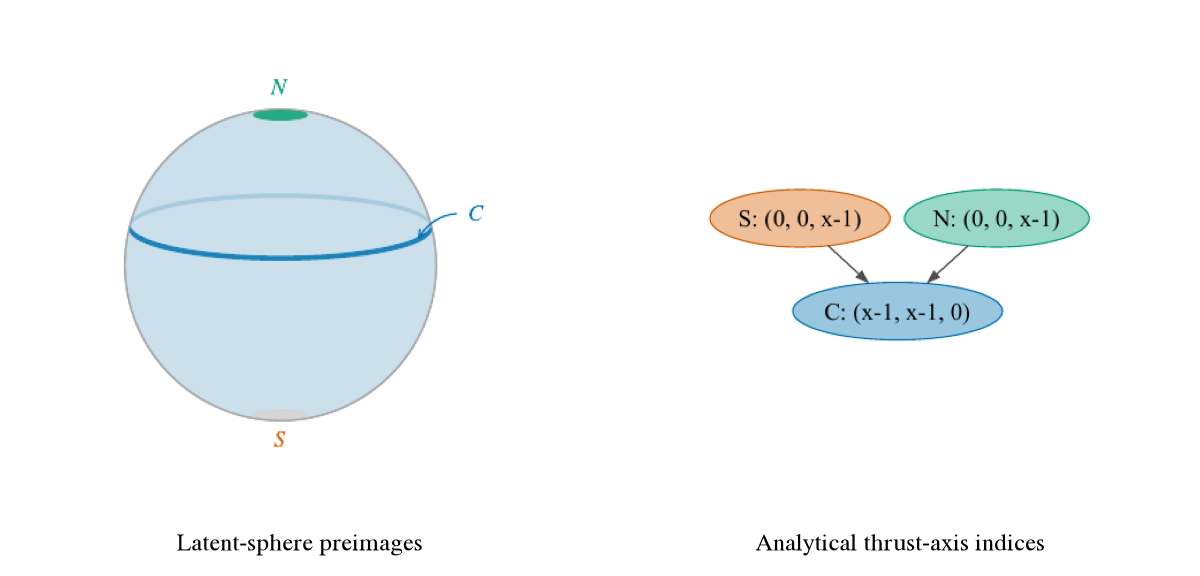

In [9]:
import notebook_attitude_figures as presentation
policy = "coning"
for names, titles in [(('native', 'aggregate'), ('Ungrouped interval graph', 'Grouped interval graph')),
                      (('preimages', 'reconstructed'), ('Latent-sphere preimages', 'Analytical thrust-axis indices'))]:
    presentation.show([FIGURES / policy / f"{name}.pdf" for name in names], titles, width=750)


## Interpretation

The selected nominal model has a pole-to-pole connection in its interval graph. For the coning model, both poles lead to the attracting component after grouping. Together with the prediction plots, these computations show how the learned models represent the two prescribed thrust-direction behaviors.

The encoder is supervised by the known thrust direction, and the training trajectories lie on $\eta=0$. This example therefore tests preservation of known reduced dynamics. The sampled cell images do not certify physical basins of attraction, and the sphere indices shown above are analytical annotations.


## Reproducibility check

This final cell runs the original replay command in a separate output directory. It repeats the computation and applies the experiment’s unchanged reference comparisons, including its original numerical tolerances. This additional run is needed only to verify reproducibility, not to view the figures above. A failed comparison raises an error and retains its log.


In [10]:
CHECK_RUN = Path(tempfile.mkdtemp(prefix="verification-", dir=OUT))
check_log = CHECK_RUN / "replay.log"
command = [str(REPLAY_PYTHON), str(EXPERIMENT.parent / "run.py"),
           "periodic", "replay", "--out", str(CHECK_RUN / "experiment")]
print("Running the original replay comparison. No retraining.", flush=True)
with check_log.open("w") as log:
    checked = subprocess.run(command, cwd=ROOT.parent / "code", env=env,
                             stdout=log, stderr=subprocess.STDOUT)
if checked.returncode:
    raise RuntimeError(f"Replay verification failed. Earlier figures remain available. See {check_log}\n"
                       + check_log.read_text()[-5000:])
verification = json.loads((CHECK_RUN / "experiment/trained/replay-verification.json").read_text())
assert verification["passed"]
print(f"Verified {len(verification['checks'])} fits against the frozen results.")


Running the original replay comparison. No retraining.


Verified 6 fits against the frozen results.
